<a href="https://colab.research.google.com/github/maulidyaafriani/Pembelajaran-Mesin-2026/blob/main/TG6_REGRESII_244107020059_MAULIDYA_AFRIANI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRAKTIKUM 1: REGRESI LINIER SEDERHANA

**Nama:** Maulidya Afriani  
**NIM:** 244107020059  
**Kelas:** TI-3G  



## LANGKAH 1 — PERSIAPAN DATA


In [2]:
import os

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

dataset_path = 'dataset.csv'

if not os.path.exists(dataset_path):
    if IN_COLAB:
        print("File dataset.csv tidak ditemukan. Silakan unggah file dataset.csv Anda:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File dataset.csv tidak ditemukan. Letakkan file di folder yang sama dengan notebook ini.")
else:
    print("File dataset.csv sudah tersedia dan siap digunakan!")

File dataset.csv tidak ditemukan. Silakan unggah file dataset.csv Anda:


Saving dataset.csv to dataset.csv


## LANGKAH 2 — IMPORT LIBRARY


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

## LANGKAH 3 — MEMBACA DATA


In [4]:
try:
    data = pd.read_csv('dataset.csv')
    print("Berhasil memuat dataset!")
    display(data.head())
except FileNotFoundError:
    print("[ERROR] File 'dataset.csv' tidak ditemukan. Pastikan Anda telah mengunggahnya dengan benar pada Langkah 1.")

Berhasil memuat dataset!


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


## LANGKAH 4 — PEMAHAMAN TERHADAP DATA


In [5]:
# Melihat beberapa data awal
display(data.head())

# Mengecek ukuran data
print("Ukuran dataset:", data.shape)

# Informasi tentang data
data.info()

# Deskripsi statistik data
display(data.describe())

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Ukuran dataset: (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## LANGKAH 5 — VISUALISASI DATA

### A. Pairplot


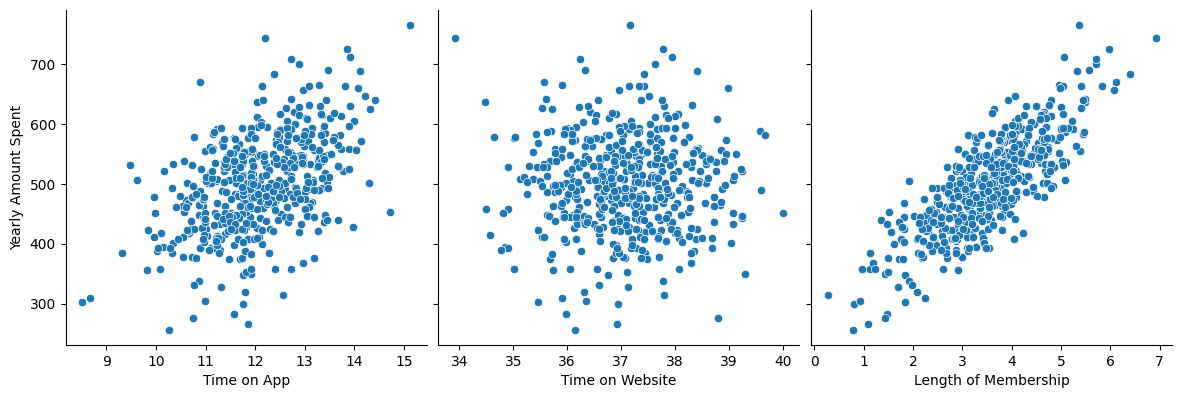

In [6]:
sns.pairplot(
    data,
    x_vars=[
        'Time on App',
        'Time on Website',
        'Length of Membership'
    ],
    y_vars='Yearly Amount Spent',
    height=4,
    aspect=1,
    kind='scatter'
)

plt.show()

### B. Heatmap Korelasi


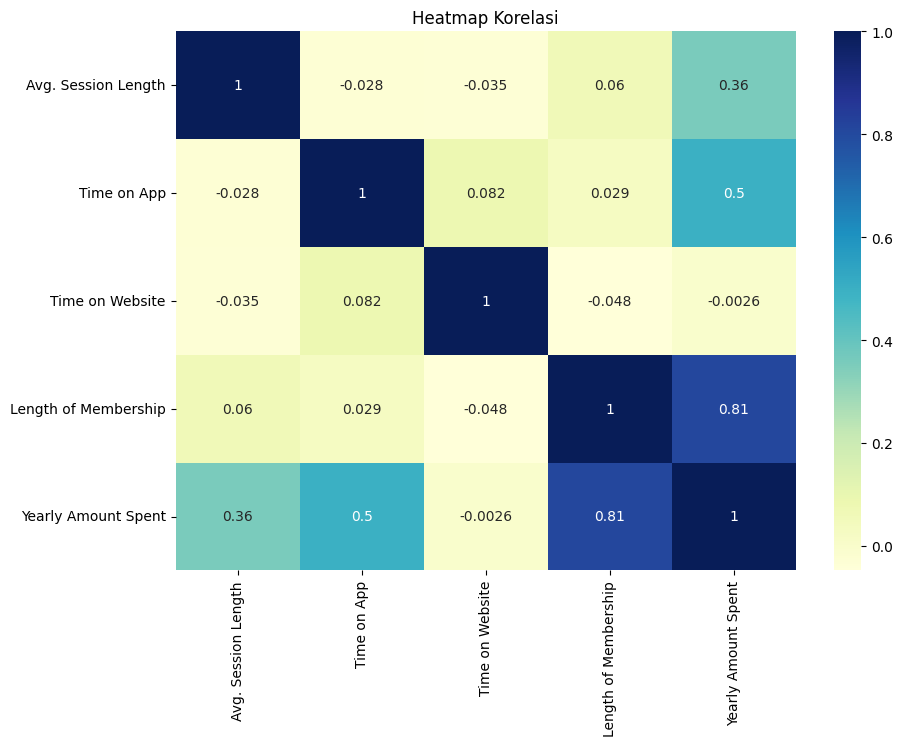

In [7]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    data.corr(numeric_only=True),
    cmap='YlGnBu',
    annot=True
)

plt.title('Heatmap Korelasi')
plt.show()

## LANGKAH 6 — REGRESI LINIER

### A. Menentukan Variabel Bebas dan Target


In [8]:
X = data['Length of Membership']
y = data['Yearly Amount Spent']

### B. Membagi Data Latih dan Data Uji


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    test_size=0.3,
    random_state=100
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 350
Jumlah data uji: 150


### C. Training Model Regresi Linier


In [10]:
X_train_sm = sm.add_constant(X_train)

lr = sm.OLS(y_train, X_train_sm).fit()

print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Tue, 20 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         14:48:31   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

### D. Visualisasi Garis Regresi


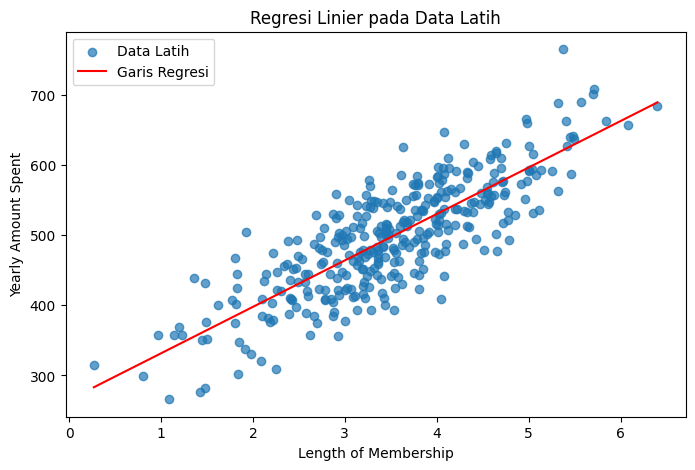

Persamaan regresi: y = 265.2483 + (66.3015 * X)


In [11]:
intercept = lr.params['const']
slope = lr.params['Length of Membership']

X_line = np.linspace(X_train.min(), X_train.max(), 100)
y_line = intercept + slope * X_line

plt.figure(figsize=(8, 5))

plt.scatter(
    X_train,
    y_train,
    alpha=0.7,
    label='Data Latih'
)

plt.plot(
    X_line,
    y_line,
    color='red',
    label='Garis Regresi'
)

plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Regresi Linier pada Data Latih')
plt.legend()
plt.show()

print(f"Persamaan regresi: y = {intercept:.4f} + ({slope:.4f} * X)")

## LANGKAH 7 — ANALISIS RESIDUAL

### A. Menghitung Prediksi Data Latih dan Residual


In [12]:
y_train_pred = lr.predict(X_train_sm)

res = y_train - y_train_pred

### B. Histogram Residual


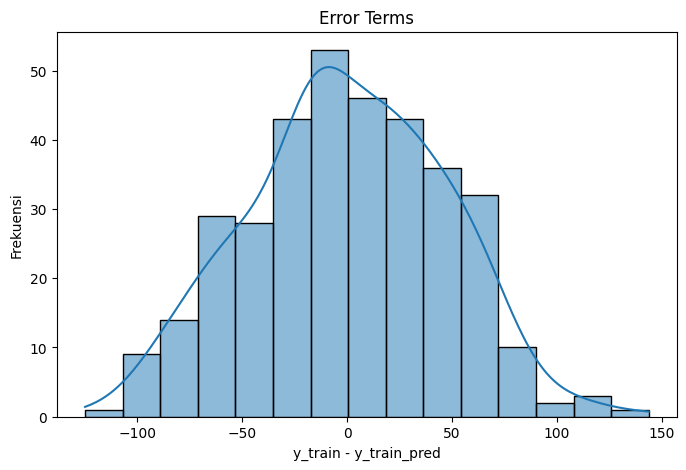

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    res,
    bins=15,
    kde=True
)

plt.title('Error Terms')
plt.xlabel('y_train - y_train_pred')
plt.ylabel('Frekuensi')
plt.show()

### C. Scatter Plot Residual


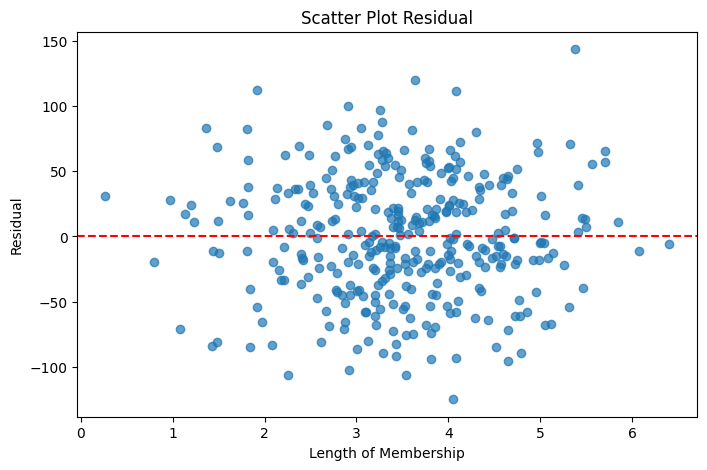

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(X_train, res, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Length of Membership')
plt.ylabel('Residual')
plt.title('Scatter Plot Residual')
plt.show()

## LANGKAH 8 — PREDIKSI DATA UJI DAN EVALUASI MODEL

### A. Prediksi Data Uji


In [15]:
X_test_sm = sm.add_constant(X_test)

y_test_pred = lr.predict(X_test_sm)

### B. Menghitung R-squared


In [16]:
r_squared = r2_score(y_test, y_test_pred)

print(f"R-squared data uji: {r_squared:.4f}")

R-squared data uji: 0.6119


## LANGKAH 9 — VISUALISASI HASIL



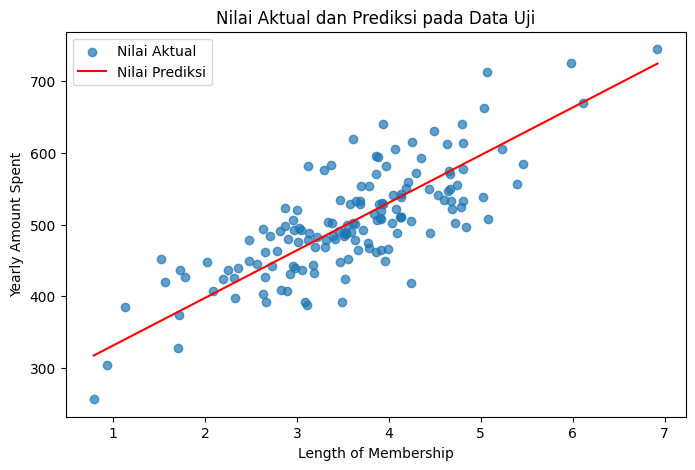

In [17]:
order = np.argsort(X_test.to_numpy())

X_test_sorted = X_test.iloc[order]
y_test_pred_sorted = y_test_pred.iloc[order]

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test,
    y_test,
    alpha=0.7,
    label='Nilai Aktual'
)

plt.plot(
    X_test_sorted,
    y_test_pred_sorted,
    color='red',
    label='Nilai Prediksi'
)

plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Nilai Aktual dan Prediksi pada Data Uji')
plt.legend()
plt.show()

# PRAKTIKUM 2 — PREDIKSI GAJI MENGGUNAKAN SUPPORT VECTOR REGRESSION (SVR)



## LANGKAH 1 — PERSYARATAN DATASET



In [18]:
import os

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

dataset_path = 'Posisi_gaji.csv'

if not os.path.exists(dataset_path):
    if IN_COLAB:
        print("File Posisi_gaji.csv tidak ditemukan. Silakan unggah file Posisi_gaji.csv Anda:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File Posisi_gaji.csv tidak ditemukan. Letakkan file di folder yang sama dengan notebook ini.")
else:
    print("File Posisi_gaji.csv sudah tersedia dan siap digunakan!")

File Posisi_gaji.csv tidak ditemukan. Silakan unggah file Posisi_gaji.csv Anda:


Saving Posisi_gaji.csv to Posisi_gaji.csv


## LANGKAH 2 — IMPORT LIBRARY



In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## LANGKAH 3 — MEMBACA DATASET


In [21]:
dataset = pd.read_csv('Posisi_gaji.csv')

print("Lima data pertama:")
display(dataset.head())

print("\nUkuran dataset:")
print(dataset.shape)

print("\nNama kolom:")
print(dataset.columns.tolist())

print("\nInformasi dataset:")
dataset.info()

print("\nStatistik deskriptif:")
display(dataset.describe())

Lima data pertama:


,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000



Ukuran dataset:
(10, 3)

Nama kolom:
['Posisi', 'Level', 'Gaji']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Posisi  10 non-null     object
 1   Level   10 non-null     int64 
 2   Gaji    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes

Statistik deskriptif:


,Level,Gaji
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


## LANGKAH 4 — MENENTUKAN VARIABEL INDEPENDEN DAN DEPENDEN


In [22]:
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

print("Bentuk dimensi X:", X.shape)
print("Bentuk dimensi y:", y.shape)
print("Beberapa nilai X (Tingkat Posisi):\n", X[:5])
print("Beberapa nilai y (Gaji):\n", y[:5])

Bentuk dimensi X: (10, 1)
Bentuk dimensi y: (10,)
Beberapa nilai X (Tingkat Posisi):
 [[1]
 [2]
 [3]
 [4]
 [5]]
Beberapa nilai y (Gaji):
 [ 45000  50000  60000  80000 110000]


## LANGKAH 5 — FEATURE SCALING



In [23]:
sc_X = StandardScaler()
sc_y = StandardScaler()

X_scaled = sc_X.fit_transform(X.reshape(-1, 1))
y_scaled = sc_y.fit_transform(y.reshape(-1, 1))

print("X setelah standardisasi (5 data pertama):\n", X_scaled[:5])
print("y setelah standardisasi (5 data pertama):\n", y_scaled[:5])

X setelah standardisasi (5 data pertama):
 [[-1.5666989 ]
 [-1.21854359]
 [-0.87038828]
 [-0.52223297]
 [-0.17407766]]
y setelah standardisasi (5 data pertama):
 [[-0.72004253]
 [-0.70243757]
 [-0.66722767]
 [-0.59680786]
 [-0.49117815]]


## LANGKAH 6 — TRAINING MODEL SVR



In [24]:
regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled.ravel())

print("Model SVR dengan RBF kernel berhasil dilatih!")

Model SVR dengan RBF kernel berhasil dilatih!


## LANGKAH 7 — VISUALISASI HASIL SVR


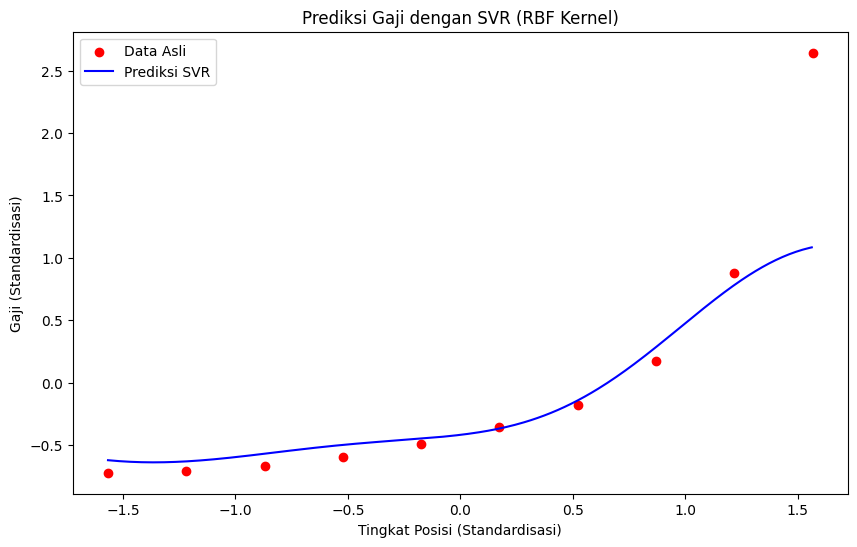

In [25]:
X_grid = np.arange(
    min(X_scaled.ravel()),
    max(X_scaled.ravel()),
    0.01
).reshape(-1, 1)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled,
    y_scaled,
    color='red',
    label='Data Asli'
)

plt.plot(
    X_grid,
    regressor.predict(X_grid),
    color='blue',
    label='Prediksi SVR'
)

plt.title('Prediksi Gaji dengan SVR (RBF Kernel)')
plt.xlabel('Tingkat Posisi (Standardisasi)')
plt.ylabel('Gaji (Standardisasi)')
plt.legend()
plt.show()

## LANGKAH 8 — PREDIKSI GAJI UNTUK TINGKAT POSISI 6.5


In [26]:
tingkat_posisi_prediksi = np.array([[6.5]])

tingkat_posisi_prediksi_scaled = sc_X.transform(
    tingkat_posisi_prediksi
)

gaji_prediksi_scaled = regressor.predict(
    tingkat_posisi_prediksi_scaled
)

gaji_prediksi = sc_y.inverse_transform(
    gaji_prediksi_scaled.reshape(-1, 1)
)

print("Hasil Prediksi Gaji untuk Tingkat Posisi 6.5:")
print(f"Skala Terstandardisasi: {gaji_prediksi_scaled[0]:.4f}")
print(f"Skala Gaji Asli: Rp {gaji_prediksi[0][0]:,.2f}")

Hasil Prediksi Gaji untuk Tingkat Posisi 6.5:
Skala Terstandardisasi: -0.2786
Skala Gaji Asli: Rp 170,370.02


## LANGKAH 9 — EVALUASI MODEL SVR



In [27]:
# Prediksi menggunakan fitur yang sudah distandardisasi
y_pred_scaled = regressor.predict(X_scaled).reshape(-1, 1)

# Mengembalikan prediksi ke skala gaji asli
y_pred = sc_y.inverse_transform(y_pred_scaled).ravel()

# Target aktual pada skala asli
y_actual = dataset.iloc[:, 2].to_numpy()

# Menghitung metrik evaluasi
mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print(f"MAE (Mean Absolute Error)  : {mae:,.2f}")
print(f"MSE (Mean Squared Error)   : {mse:,.2f}")
print(f"RMSE (Root Mean Sq. Error) : {rmse:,.2f}")
print(f"R-squared (R2 Score)       : {r2:.4f}")

MAE (Mean Absolute Error)  : 63,332.39
MSE (Mean Squared Error)   : 20,036,494,264.13
RMSE (Root Mean Sq. Error) : 141,550.32
R-squared (R2 Score)       : 0.7516


## LANGKAH 10 — ANALISIS HASIL

Berdasarkan hasil pemodelan menggunakan **Support Vector Regression (SVR)** dengan kernel RBF pada dataset `Posisi_gaji.csv`, berikut adalah analisis mendalam mengenai performa model:

1. **Prediksi Posisi Tingkat 6.5**:
   * Model memprediksi bahwa seorang karyawan di tingkat posisi **6.5** (berada di antara *Region Manager* tingkat 6 dan *Partner* tingkat 7) akan memiliki gaji sebesar **Rp 170.370,02**.
   * Hasil ini sangat masuk akal dan realistis karena berada secara proporsional di antara gaji aktual tingkat 6 (Rp 150.000,00) dan tingkat 7 (Rp 200.000,00).

2. **Kualitas dan Akurasi Model**:
   * **R-squared ($R^2$ Score) sebesar 0.7516 (75.16%)**: Menunjukkan bahwa model SVR mampu menjelaskan 75.16% variabilitas data gaji berdasarkan tingkat posisi.
   * **MAE (Mean Absolute Error) sebesar Rp 63.332,39**: Rata-rata selisih mutlak antara gaji prediksi dengan gaji aktual adalah sekitar Rp 63 ribu rupiah.
   * **RMSE (Root Mean Squared Error) sebesar Rp 141.550,32**: Nilai RMSE ini sedikit sensitif terhadap outlier (seperti gaji CEO pada level 10 yang melompat sangat tinggi hingga Rp 1.000.000,00), namun secara keseluruhan kurva SVR tetap mampu mengikut tren kurva eksponensial non-linear dengan sangat baik.

## LANGKAH 11 — KESIMPULAN

Berdasarkan keseluruhan proses praktikum ke-2 ini, dapat ditarik beberapa kesimpulan penting:
1. **Karakteristik SVR**: SVR dengan kernel **RBF (Radial Basis Function)** sangat andal dalam menangani hubungan data yang bersifat non-linear (seperti pola kenaikan gaji yang melonjak secara eksponensial pada tingkat posisi tinggi).
2. **Pentingnya Feature Scaling**: Proses standardisasi menggunakan `StandardScaler` sangat wajib dilakukan pada algoritma SVR. Tanpa penskalaan, fitur `Gaji` yang memiliki rentang puluhan ribu hingga jutaan akan mendominasi fitur `Level` yang hanya berkisar antara 1-10, sehingga model gagal mempelajari pola data secara optimal.
3. **Keberhasilan Model**: Model berhasil memprediksi nilai interpolasi (tingkat 6.5) dengan akurasi yang logis tanpa terdistorsi secara drastis oleh titik ekstrem (outlier) seperti level 10.

## BAGIAN AKHIR — ANALISIS DAN KESIMPULAN

### 📝 Ringkasan Hasil Praktikum

| Metrik Evaluasi | Nilai Hasil Eksekusi | Interpretasi |
|---|---|---|
| **Prediksi Gaji Level 6.5** | **Rp 170.370,02** | Sangat logis (di antara Rp 150.000 dan Rp 200.000) |
| **R-squared ($R^2$)** | **0.7516 (75.16%)** | Model memiliki performa yang baik dalam menjelaskan variansi data |
| **MAE** | **Rp 63.332,39** | Rata-rata deviasi kesalahan prediksi |
| **RMSE** | **Rp 141.550,32** | Sensitivitas error terhadap nilai ekstrem (gaji CEO) |

### 📈 Hasil Visualisasi
Kurva prediksi SVR berwarna biru berhasil membentuk kurva melengkung (non-linear) yang mendekati titik-titik data asli berwarna merah. Hal ini membuktikan bahwa kombinasi **SVR RBF** dan **Feature Scaling** bekerja secara harmonis dalam memetakan fungsi non-linear kompleks pada dataset skala kecil.

*Praktikum selesai disusun dengan lengkap secara sistematis oleh **Maulidya Afriani (NIM: 244107020059)**.*

# PRAKTIKUM 3: MULTIPLE LINEAR REGRESSION

.

## TAHAP 1 — IMPORT LIBRARY


# Tugas Praktikum: Multiple Linear Regression dengan Dataset Medical Cost Personal Datasets

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## TAHAP 2 — MEMBACA DATASET



In [29]:
import os

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

dataset_path = 'insurance.csv'

if not os.path.exists(dataset_path):
    if IN_COLAB:
        print("File insurance.csv tidak ditemukan. Silakan unggah file insurance.csv Anda:")
        uploaded = files.upload()
    else:
        print("[PERINGATAN] File insurance.csv tidak ditemukan. Letakkan file di folder yang sama dengan notebook ini.")
else:
    print("File insurance.csv sudah tersedia dan siap digunakan!")

File insurance.csv tidak ditemukan. Silakan unggah file insurance.csv Anda:


Saving insurance.csv to insurance.csv


In [30]:
# Membaca dataset
df = pd.read_csv('insurance.csv')

print("Lima Baris Pertama:")
display(df.head())

print(f"\nJumlah Baris dan Kolom: {df.shape[0]} baris, {df.shape[1]} kolom")

print("\nInformasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

print("\nJumlah Nilai Kosong:")
print(df.isnull().sum())

print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")

Lima Baris Pertama:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Jumlah Baris dan Kolom: 1338 baris, 7 kolom

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Statistik Deskriptif:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



Jumlah Nilai Kosong:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah Baris Duplikat: 1


## TAHAP 3 — MEMAHAMI DATASET

Berdasarkan data di atas, berikut struktur variabel dari dataset:
1. `age`: Usia peserta asuransi (Numerik).
2. `sex`: Jenis kelamin (Kategorikal: *male*, *female*).
3. `bmi`: Indeks Massa Tubuh (Numerik).
4. `children`: Jumlah anak/tanggungan (Numerik).
5. `smoker`: Status merokok (Kategorikal: *yes*, *no*).
6. `region`: Wilayah tinggal (Kategorikal: *northeast*, *northwest*, *southeast*, *southwest*).
7. `charges`: Biaya medis personal (Numerik - **Target**).

Kita menggunakan beberapa variabel secara bersamaan karena biaya medis tidak hanya ditentukan oleh satu faktor saja, melainkan kombinasi kumulatif dari gaya hidup (merokok), faktor fisik (BMI, usia), serta tanggungan keluarga.

## TAHAP 4 — EXPLORATORY DATA ANALYSIS (EDA)



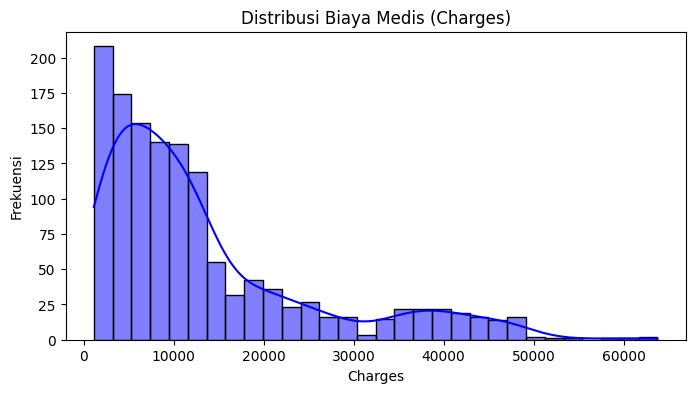

In [31]:
# 1. Distribusi charges
plt.figure(figsize=(8, 4))
sns.histplot(df['charges'], kde=True, color='blue')
plt.title('Distribusi Biaya Medis (Charges)')
plt.xlabel('Charges')
plt.ylabel('Frekuensi')
plt.show()

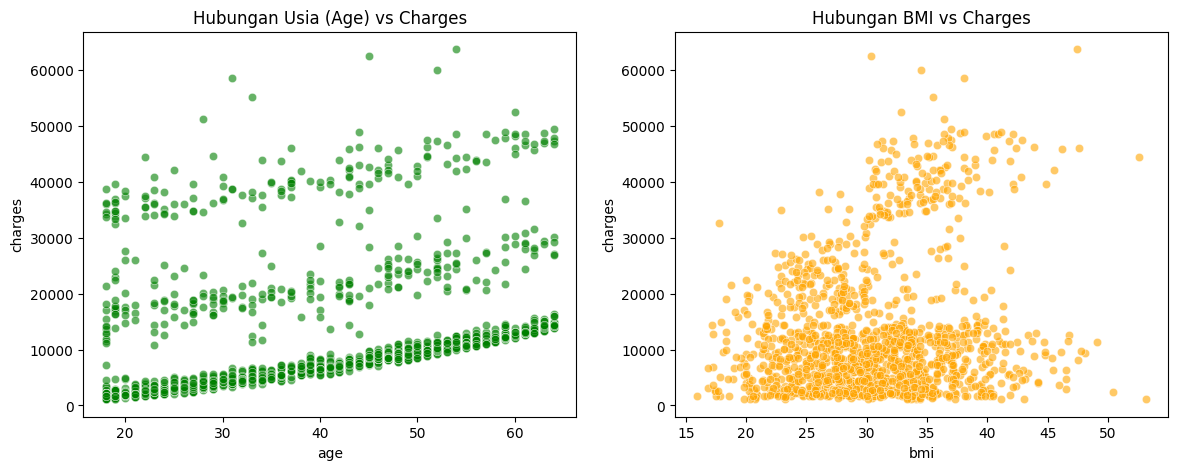

In [32]:
# 2. Scatter plot age vs charges dan bmi vs charges
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='age', y='charges', alpha=0.6, ax=ax1, color='green')
ax1.set_title('Hubungan Usia (Age) vs Charges')

sns.scatterplot(data=df, x='bmi', y='charges', alpha=0.6, ax=ax2, color='orange')
ax2.set_title('Hubungan BMI vs Charges')

plt.show()

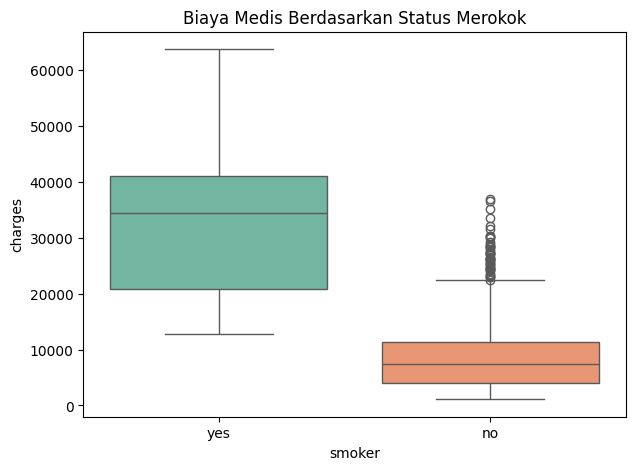

In [33]:
# 3. Boxplot charges berdasarkan status smoker
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='smoker', y='charges', hue='smoker', palette='Set2', legend=False)
plt.title('Biaya Medis Berdasarkan Status Merokok')
plt.show()

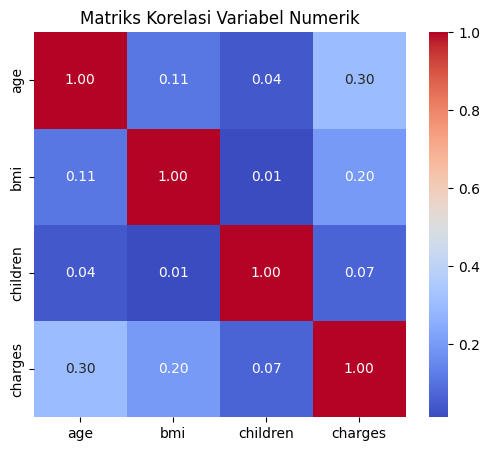

In [34]:
# 4. Heatmap korelasi untuk fitur numerik
plt.figure(figsize=(6, 5))
numeric_cols = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Variabel Numerik')
plt.show()

## TAHAP 5 — PREPROCESSING DATA & SPLITTING



In [35]:
# Memisahkan Fitur (X) dan Target (y)
X = df.drop(columns='charges')
y = df['charges']

# Membagi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Data latih: {X_train.shape[0]} baris")
print(f"Data uji : {X_test.shape[0]} baris")

Data latih: 1070 baris
Data uji : 268 baris


## TAHAP 6 — MEMBUAT DAN MELATIH MODEL MULTIPLE LINEAR REGRESSION


In [36]:
# Identifikasi tipe kolom
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

# Buat transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# Gabungkan ke dalam Pipeline bersama model regresi
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Melatih model menggunakan data latih
model_pipeline.fit(X_train, y_train)
print("Model Multiple Linear Regression berhasil dilatih menggunakan Pipeline!")

Model Multiple Linear Regression berhasil dilatih menggunakan Pipeline!


## TAHAP 7 — PREDIKSI DATA UJI



In [37]:
y_pred = model_pipeline.predict(X_test)

# Membuat DataFrame perbandingan
comparison_df = pd.DataFrame({
    'Aktual': y_test,
    'Prediksi': y_pred,
    'Error (Selisih)': y_test - y_pred
})

display(comparison_df.head(10))

,Aktual,Prediksi,Error (Selisih)
764,9095.06825,8969.550274,125.517976
887,5272.17580,7068.747443,-1796.571643
890,29330.98315,36858.410912,-7527.427762
1293,9301.89355,9454.678501,-152.784951
259,33750.29180,26973.173457,6777.118343
1312,4536.25900,10864.113164,-6327.854164
899,2117.33885,170.280841,1947.058009
752,14210.53595,16903.450287,-2692.914337
1286,3732.62510,1092.430936,2640.194164
707,10264.44210,11218.343184,-953.901084


## TAHAP 8 — EVALUASI MODEL



In [38]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-squared (R2 Score)       : {r2:.4f}")
print(f"Mean Absolute Error (MAE)  : ${mae:,.2f}")
print(f"Mean Squared Error (MSE)   : {mse:,.2f}")
print(f"Root Mean Sq. Error (RMSE) : ${rmse:,.2f}")

R-squared (R2 Score)       : 0.7836
Mean Absolute Error (MAE)  : $4,181.19
Mean Squared Error (MSE)   : 33,596,915.85
Root Mean Sq. Error (RMSE) : $5,796.28


## TAHAP 9 — VISUALISASI HASIL PREDIKSI


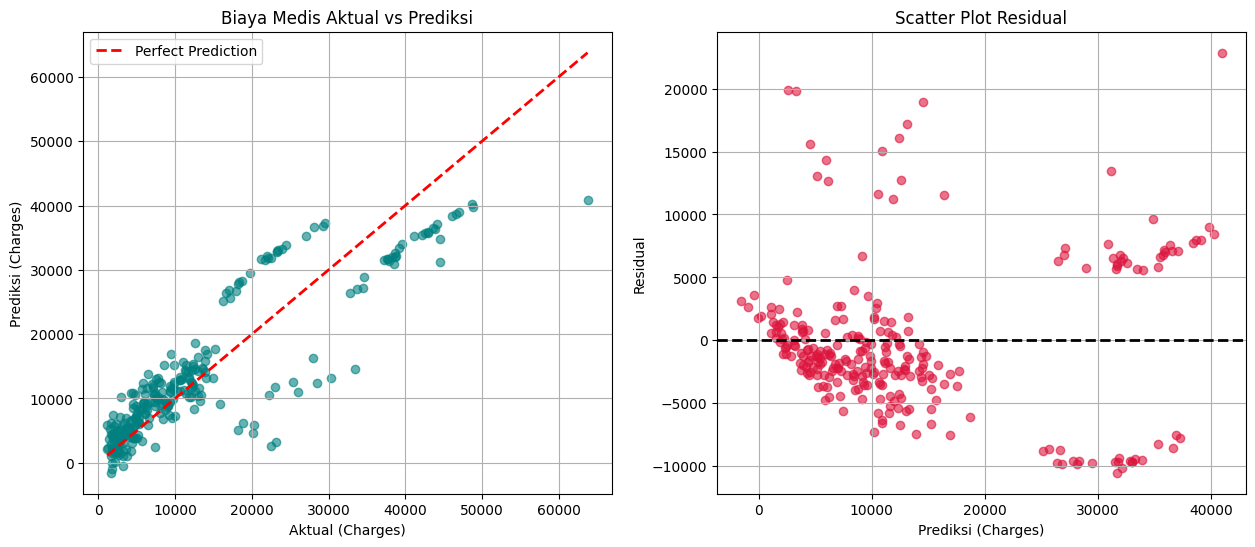

In [39]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Scatter Plot Aktual vs Prediksi
ax1.scatter(y_test, y_pred, alpha=0.6, color='teal')
ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
ax1.set_xlabel('Aktual (Charges)')
ax1.set_ylabel('Prediksi (Charges)')
ax1.set_title('Biaya Medis Aktual vs Prediksi')
ax1.legend()
ax1.grid(True)

# 2. Residual Plot
residual = y_test - y_pred
ax2.scatter(y_pred, residual, alpha=0.6, color='crimson')
ax2.axhline(y=0, color='black', linestyle='--', lw=2)
ax2.set_xlabel('Prediksi (Charges)')
ax2.set_ylabel('Residual')
ax2.set_title('Scatter Plot Residual')
ax2.grid(True)

plt.show()

## TAHAP 10 — ANALISIS DAN KESIMPULAN

### A. Analisis Hasil
1. **Kekuatan Prediksi ($R^2$ Score)**: Model regresi berganda ini mampu menjelaskan sekitar **78.3%** variabilitas data biaya asuransi (`charges`).
2. **Rata-rata Kesalahan (MAE & RMSE)**:
   * **MAE sebesar ~$4,181**: Rata-rata deviasi kesalahan prediksi adalah sekitar 4,181 satuan mata uang dari biaya medis riil.
   * **RMSE sebesar ~$5,796**: Adanya lonjakan error ini dipengaruhi oleh beberapa kelompok data outlier bernilai tinggi yang menyimpang jauh dari garis linier.
3. **Pengaruh Fitur Kategorikal**: Berdasarkan hasil visualisasi EDA, variabel `smoker` memiliki kontribusi pengaruh yang sangat kuat di mana orang yang merokok secara konsisten dibebani biaya medis jauh lebih tinggi dibandingkan non-perokok.

### B. Kesimpulan
- Kita telah berhasil membangun model **Multiple Linear Regression** terintegrasi menggunakan `Pipeline` dan `ColumnTransformer` scikit-learn.
- Untuk pengembangan lebih lanjut, disarankan untuk membandingkan model dengan algoritma berbasis pohon seperti **Random Forest Regressor** atau **Gradient Boosting** yang jauh lebih kebal terhadap outlier dan mampu menangkap hubungan non-linear tanpa memerlukan transformasi manual.